[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/obss/sahi/blob/main/demo/inference_for_ultralytics.ipynb)

## 0. Preperation

- Install latest version of SAHI and ultralytics:

In [190]:
!pip install -U torch sahi ultralytics onnxruntime
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 73.0 MB/s eta 0:00:00
  Attempting uninstall: onnxruntime
    Found existing installation: onnxruntime 1.21.0
    Uninstalling onnxruntime-1.21.0:
      Successfully uninstalled onnxruntime-1.21.0


In [191]:
#import os
#os.getcwd()

- Import required modules:

In [192]:
from sahi import AutoDetectionModel
from sahi.utils.cv import read_image
from sahi.utils.file import download_from_url
from sahi.predict import get_prediction, get_sliced_prediction, predict
from IPython.display import Image

- Download two test images:

In [193]:
download_from_url('https://raw.githubusercontent.com/obss/sahi/main/demo/demo_data/small-vehicles1.jpeg', 'demo_data/small-vehicles1.jpeg')
download_from_url('https://raw.githubusercontent.com/obss/sahi/main/demo/demo_data/terrain2.png', 'demo_data/terrain2.png')
download_from_url('https://ultralytics.com/images/boats.jpg', 'demo_data/obb_test_image.png')

In [194]:
category_mapping = {
    "0": "break",
    "1": "crush",
    "2": "debris",
    "3": "debrishalo",
    "4": "dust",
    "5": "edgecrack",
    "6": "hangingchad",
    "7": "hole",
    "8": "streak",
    "9": "thinspot",
    "10": "worm"
}

## 1. Standard Inference with an Ultralytics Model

In [195]:
import cv2
import numpy as np

def letterbox(image, target_size=(640, 640), color=(114, 114, 114), auto=False, scaleFill=False, scaleup=True):
    """
    Resize and pad image to fit target size while keeping aspect ratio.

    Args:
        image (np.ndarray): Input image (BGR or RGB).
        target_size (tuple): Desired size in the format (width, height).
        color (tuple): Padding color. Default is gray (114,114,114).
        auto (bool): Use minimum rectangle that is a multiple of 32.
        scaleFill (bool): Stretch image to fill the target size (no aspect ratio preservation).
        scaleup (bool): Allow scaling up the image.

    Returns:
        padded_image: The resized and padded image.
        ratio: (width_scale, height_scale)
        (dw, dh): padding added on width and height
    """
    shape = image.shape[:2]  # current shape [height, width]
    target_w, target_h = target_size

    # Scale ratio (new / old)
    scale = min(target_w / shape[1], target_h / shape[0])
    if not scaleup:
        scale = min(scale, 1.0)

    # Compute new unpadded size
    new_w = int(round(shape[1] * scale))
    new_h = int(round(shape[0] * scale))

    # Compute padding
    dw = target_w - new_w
    dh = target_h - new_h
    if auto:  # minimum rectangle, multiple of 32
        dw = np.mod(dw, 32)
        dh = np.mod(dh, 32)
    elif scaleFill:  # stretch to fill the shape
        new_w, new_h = target_w, target_h
        dw, dh = 0, 0
        scale = (target_w / shape[1], target_h / shape[0])

    dw /= 2  # divide padding into 2 sides
    dh /= 2

    # Resize image
    resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    # Add border
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    padded_image = cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=color)

    return padded_image, (scale, scale), (dw, dh)

import cv2

img = cv2.imread("3207520_aug_3051.jpg")
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

letterboxed_img, ratio, (dw, dh) = letterbox(img_rgb, target_size=(960, 960))

- Instantiate a detection model by defining model weight path and other parameters:

In [203]:
detection_model = AutoDetectionModel.from_pretrained(
    model_type='yolov8onnx',
    model_path="best.onnx", # any yolov8/yolov9/yolo11/yolo12/rt-detr det model is supported
    confidence_threshold=0.1,
    iou_threshold=0.7,
    device="gpu", # or 'cuda:0' if GPU is available
    category_mapping=category_mapping
)

- Perform prediction by feeding the get_prediction function with an image path and a DetectionModel instance:

In [204]:
result = get_prediction("demo_data/small-vehicles1.jpeg", detection_model)

- Or perform prediction by feeding the get_prediction function with a numpy image and a DetectionModel instance:

In [205]:
result = get_prediction(letterboxed_img, detection_model)

- Visualize predicted bounding boxes and masks over the original image:

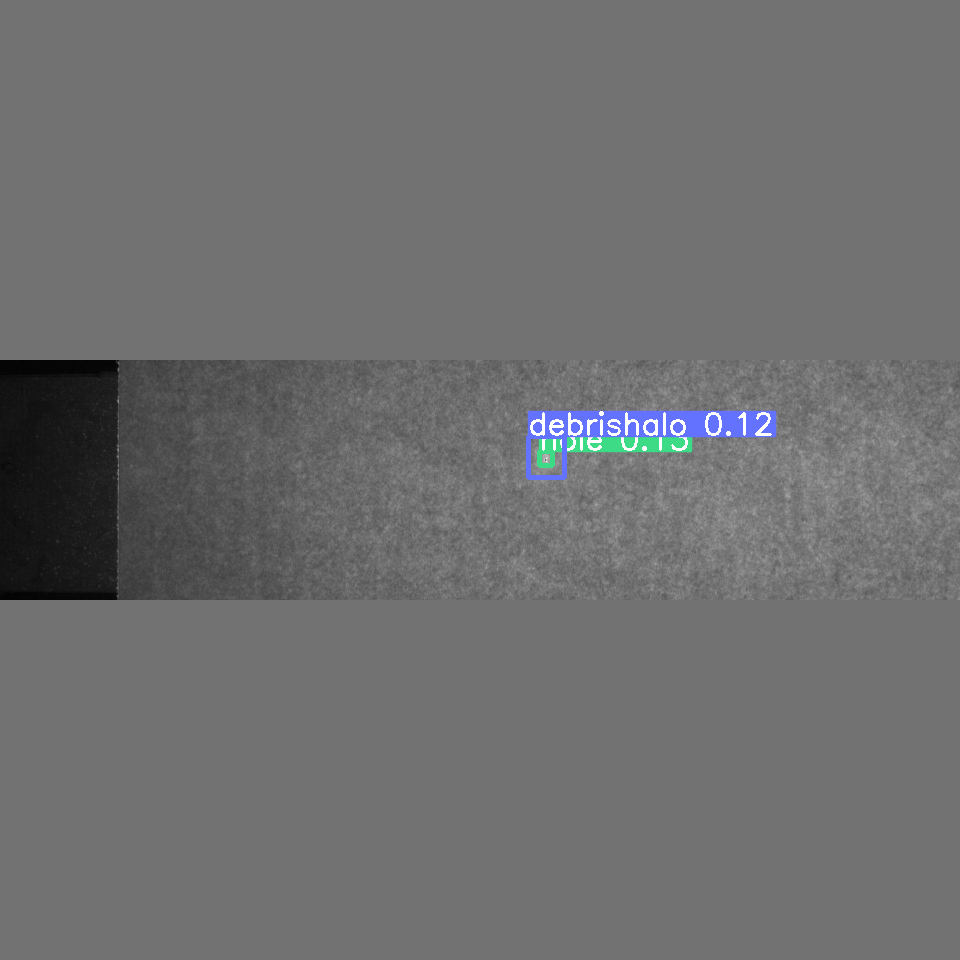

In [207]:
result.export_visuals(export_dir="demo_data/", hide_conf=False)

Image("demo_data/prediction_visual.png")

## 2. Sliced Inference with a YOLOv8/YOLO11 Model

- To perform sliced prediction we need to specify slice parameters. In this example we will perform prediction over slices of 256x256 with an overlap ratio of 0.2:

In [ ]:
result = get_sliced_prediction(
    letterboxed_img,
    detection_model,
    slice_height = 128,
    slice_width = 256,
    overlap_height_ratio = 0.4,
    overlap_width_ratio = 0.4
)

Performing prediction on 72 slices.


- Visualize predicted bounding boxes and masks over the original image:

In [ ]:
result.export_visuals(export_dir="demo_data/", hide_conf=False)

Image("demo_data/prediction_visual.png")

## 3. Prediction Result

- Predictions are returned as [sahi.prediction.PredictionResult](sahi/prediction.py), you can access the object prediction list as:

In [210]:
object_prediction_list = result.object_prediction_list

In [211]:
object_prediction_list[0]

ObjectPrediction<
    bbox: BoundingBox: <(np.float32(542.0), np.float32(453.0), np.float32(549.0), np.float32(460.0)), w: 7.0, h: 7.0>,
    mask: None,
    score: PredictionScore: <value: 0.1948549449443817>,
    category: Category: <id: 2, name: debris>>

- ObjectPrediction's can be converted to [COCO annotation](https://cocodataset.org/#format-data) format:

In [212]:
result.to_coco_annotations()[:3]

[{'image_id': None,
  'bbox': [542.0, 453.0, 7.0, 7.0],
  'score': 0.1948549449443817,
  'category_id': 2,
  'category_name': 'debris',
  'segmentation': [],
  'iscrowd': 0,
  'area': 49},
 {'image_id': None,
  'bbox': [528.0, 436.0, 36.0, 41.0],
  'score': 0.17119848728179932,
  'category_id': 3,
  'category_name': 'debrishalo',
  'segmentation': [],
  'iscrowd': 0,
  'area': 1476},
 {'image_id': None,
  'bbox': [539.0, 451.0, 13.0, 14.0],
  'score': 0.12895601987838745,
  'category_id': 7,
  'category_name': 'hole',
  'segmentation': [],
  'iscrowd': 0,
  'area': 182}]

- ObjectPrediction's can be converted to [COCO prediction](https://github.com/i008/COCO-dataset-explorer) format:

In [ ]:
result.to_coco_predictions(image_id=1)[:3]

[{'image_id': 1,
  'bbox': [447.7891845703125,
   309.07598876953125,
   47.58802032470703,
   33.136810302734375],
  'score': 0.9221271276473999,
  'category_id': 2,
  'category_name': 'car',
  'segmentation': [],
  'iscrowd': 0,
  'area': 1576},
 {'image_id': 1,
  'bbox': [832.6661224365234,
   308.70198822021484,
   41.41694641113281,
   36.017311096191406],
  'score': 0.8925901055335999,
  'category_id': 2,
  'category_name': 'car',
  'segmentation': [],
  'iscrowd': 0,
  'area': 1491},
 {'image_id': 1,
  'bbox': [766.1792449951172,
   260.6599998474121,
   27.710586547851562,
   23.558719635009766],
  'score': 0.8334103226661682,
  'category_id': 2,
  'category_name': 'car',
  'segmentation': [],
  'iscrowd': 0,
  'area': 652}]

- ObjectPrediction's can be converted to [imantics](https://github.com/jsbroks/imantics) annotation format:

In [ ]:
!pip install imantics
result.to_imantics_annotations()[:3]

- ObjectPrediction's can be converted to [fiftyone](https://github.com/voxel51/fiftyone) detection format:

In [ ]:
!pip install fiftyone
result.to_fiftyone_detections()[:3]

## 4. Batch Prediction

- Set model and directory parameters:

In [ ]:
model_type = "ultralytics"
model_path = 'yolo11n.pt'
model_device = "cpu" # or 'cuda:0' if GPU is available
model_confidence_threshold = 0.4

slice_height = 256
slice_width = 256
overlap_height_ratio = 0.2
overlap_width_ratio = 0.2

source_image_dir = "demo_data/"

- Perform sliced inference on given folder:

In [ ]:
predict(
    model_type=model_type,
    model_path=model_path,
    model_device=model_device,
    model_confidence_threshold=model_confidence_threshold,
    source=source_image_dir,
    slice_height=slice_height,
    slice_width=slice_width,
    overlap_height_ratio=overlap_height_ratio,
    overlap_width_ratio=overlap_width_ratio,
)

There are 4 listed files in folder: demo_data/


Performing inference on images:   0%|          | 0/4 [00:00<?, ?it/s]

Performing prediction on 60 slices.


Performing inference on images:  25%|██▌       | 1/4 [00:01<00:05,  1.82s/it]

Prediction time is: 1737.92 ms
Performing prediction on 15 slices.


...

Prediction time is: 390.09 ms
Performing prediction on 15 slices.


Performing inference on images:  75%|███████▌  | 3/4 [00:02<00:00,  1.32it/s]

Prediction time is: 420.70 ms
Performing prediction on 20 slices.


Performing inference on images: 100%|██████████| 4/4 [00:03<00:00,  1.22it/s]

Prediction time is: 524.14 ms
Prediction results are successfully exported to runs\predict\exp5


# 5 Sliced Segmentation

Run the same steps for YOLO11 segmentation model:

In [ ]:
detection_model_seg = AutoDetectionModel.from_pretrained(
    model_type='ultralytics',
    model_path='yolo11n-seg.pt', # any yolov8/yolov9/yolo11/yolo12 seg model is supported
    confidence_threshold=0.3,
    device="cpu", # or 'cuda:0' if GPU is available
)

im = read_image("demo_data/small-vehicles1.jpeg")

- Perform standard segmentation:

In [ ]:
result = get_prediction(im, detection_model_seg)

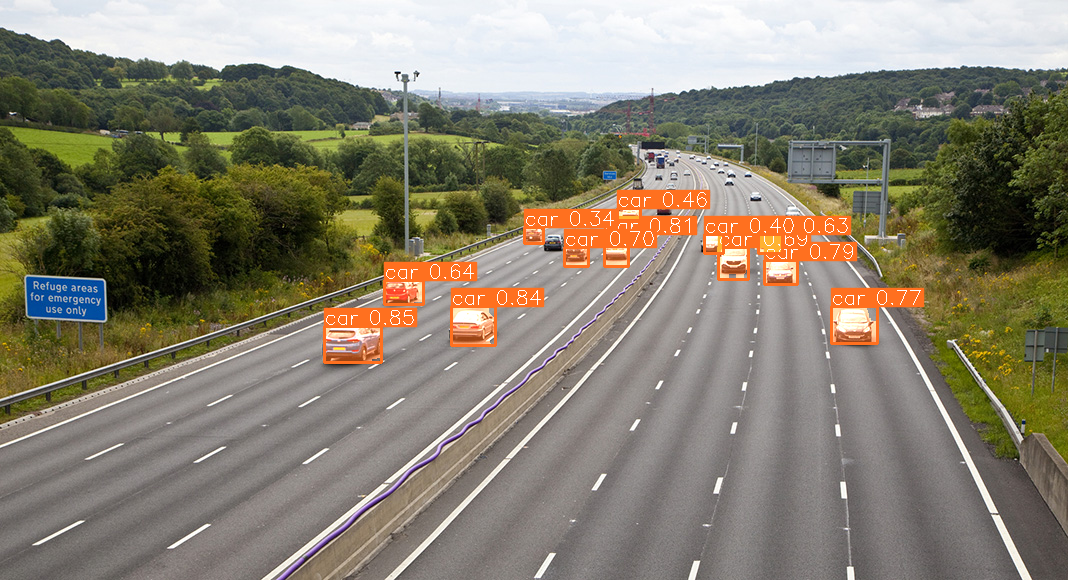

In [ ]:
result.export_visuals(export_dir="demo_data/")

Image("demo_data/prediction_visual.png")

- Repeat for sliced segmentation:

In [ ]:
result = get_sliced_prediction(
    im,
    detection_model_seg,
    slice_height = 256,
    slice_width = 256,
    overlap_height_ratio = 0.2,
    overlap_width_ratio = 0.2
)

Performing prediction on 15 slices.


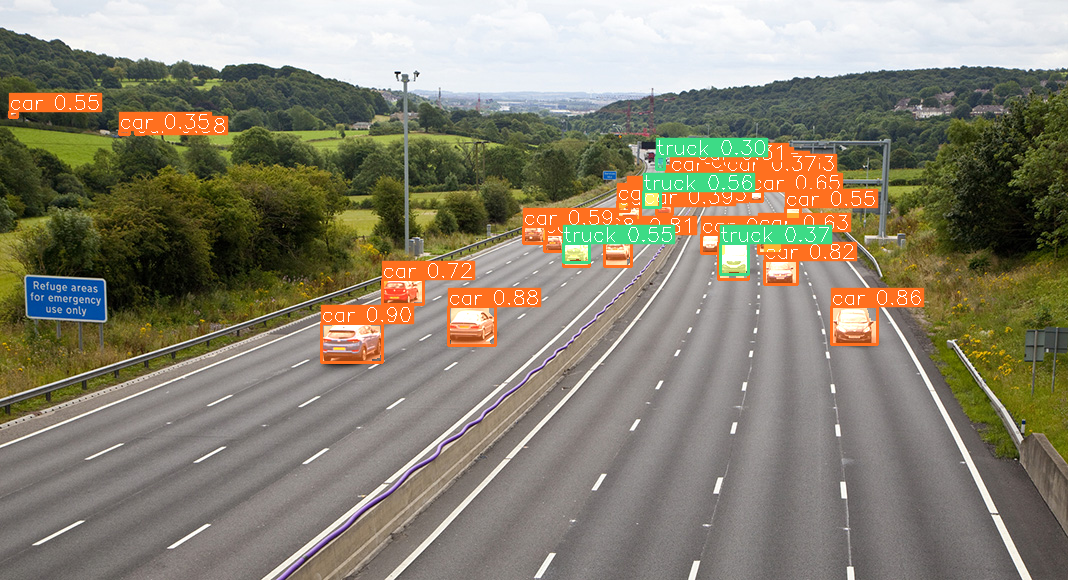

In [ ]:
result.export_visuals(export_dir="demo_data/")

Image("demo_data/prediction_visual.png")

Sliced predictions are much better!

- Observe the prediction format:

In [ ]:
object_prediction_list = result.object_prediction_list
object_prediction_list[0]

ObjectPrediction<
    bbox: BoundingBox: <(833, 309, 873, 343), w: 40, h: 34>,
    mask: <sahi.annotation.Mask object>,
    score: PredictionScore: <value: 0.9211080074310303>,
    category: Category: <id: 2, name: car>>

In [ ]:
object_prediction_list[0].mask.segmentation

[[837,
  313,
  836,
  313,
  836,
  315,
  835,
  316,
  835,
  317,
  835,
  318,
  834,
  319,
  833,
  320,
  833,
  336,
  834,
  337,
  834,
  338,
  834,
  339,
  835,
  340,
  835,
  341,
  836,
  342,
  837,
  342,
  841,
  342,
  846,
  342,
  863,
  342,
  864,
  343,
  869,
  343,
  870,
  343,
  871,
  342,
  871,
  340,
  872,
  340,
  872,
  339,
  873,
  338,
  873,
  323,
  873,
  321,
  873,
  320,
  872,
  319,
  872,
  318,
  871,
  318,
  866,
  313,
  867,
  312,
  865,
  310,
  863,
  310,
  862,
  309,
  841,
  309,
  840,
  309,
  839,
  310,
  839,
  311,
  838,
  311,
  838,
  312]]

In [ ]:
predict(
    model_type=model_type,
    model_path=model_path,
    model_device=model_device,
    model_confidence_threshold=model_confidence_threshold,
    source=source_image_dir,
    slice_height=slice_height,
    slice_width=slice_width,
    overlap_height_ratio=overlap_height_ratio,
    overlap_width_ratio=overlap_width_ratio,
)

There are 3 listed files in folder: demo_data/


Performing inference on images:   0%|                                                | 0/3 [00:00<?, ?it/s]

Performing prediction on 15 slices.


Performing inference on images:  33%|█████████████▎                          | 1/3 [00:01<00:03,  1.74s/it]

Prediction time is: 1615.49 ms
Performing prediction on 15 slices.


Performing inference on images:  67%|██████████████████████████▋             | 2/3 [00:03<00:01,  1.70s/it]

Prediction time is: 1593.49 ms
Performing prediction on 20 slices.


Performing inference on images: 100%|████████████████████████████████████████| 3/3 [00:05<00:00,  1.86s/it]

Prediction time is: 2070.87 ms
Prediction results are successfully exported to runs/predict/exp9


# 7 Sliced OBB Prediction


In [ ]:
detection_model_obb = AutoDetectionModel.from_pretrained(
    model_type='ultralytics',
    model_path='yolo11n-obb.pt', # any yolov8/yolov9/yolo11/yolo12 obb model is supported
    confidence_threshold=0.3,
    device="cuda:0", # or 'cuda:0' if GPU is available
)

im = read_image("demo_data/obb_test_image.png")


In [ ]:
result = get_sliced_prediction(
    im,
    detection_model_obb,
    slice_height = 512,
    slice_width = 512,
    overlap_height_ratio = 0.2,
    overlap_width_ratio = 0.2,
    #perform_standard_pred = False
)

Performing prediction on 15 slices.


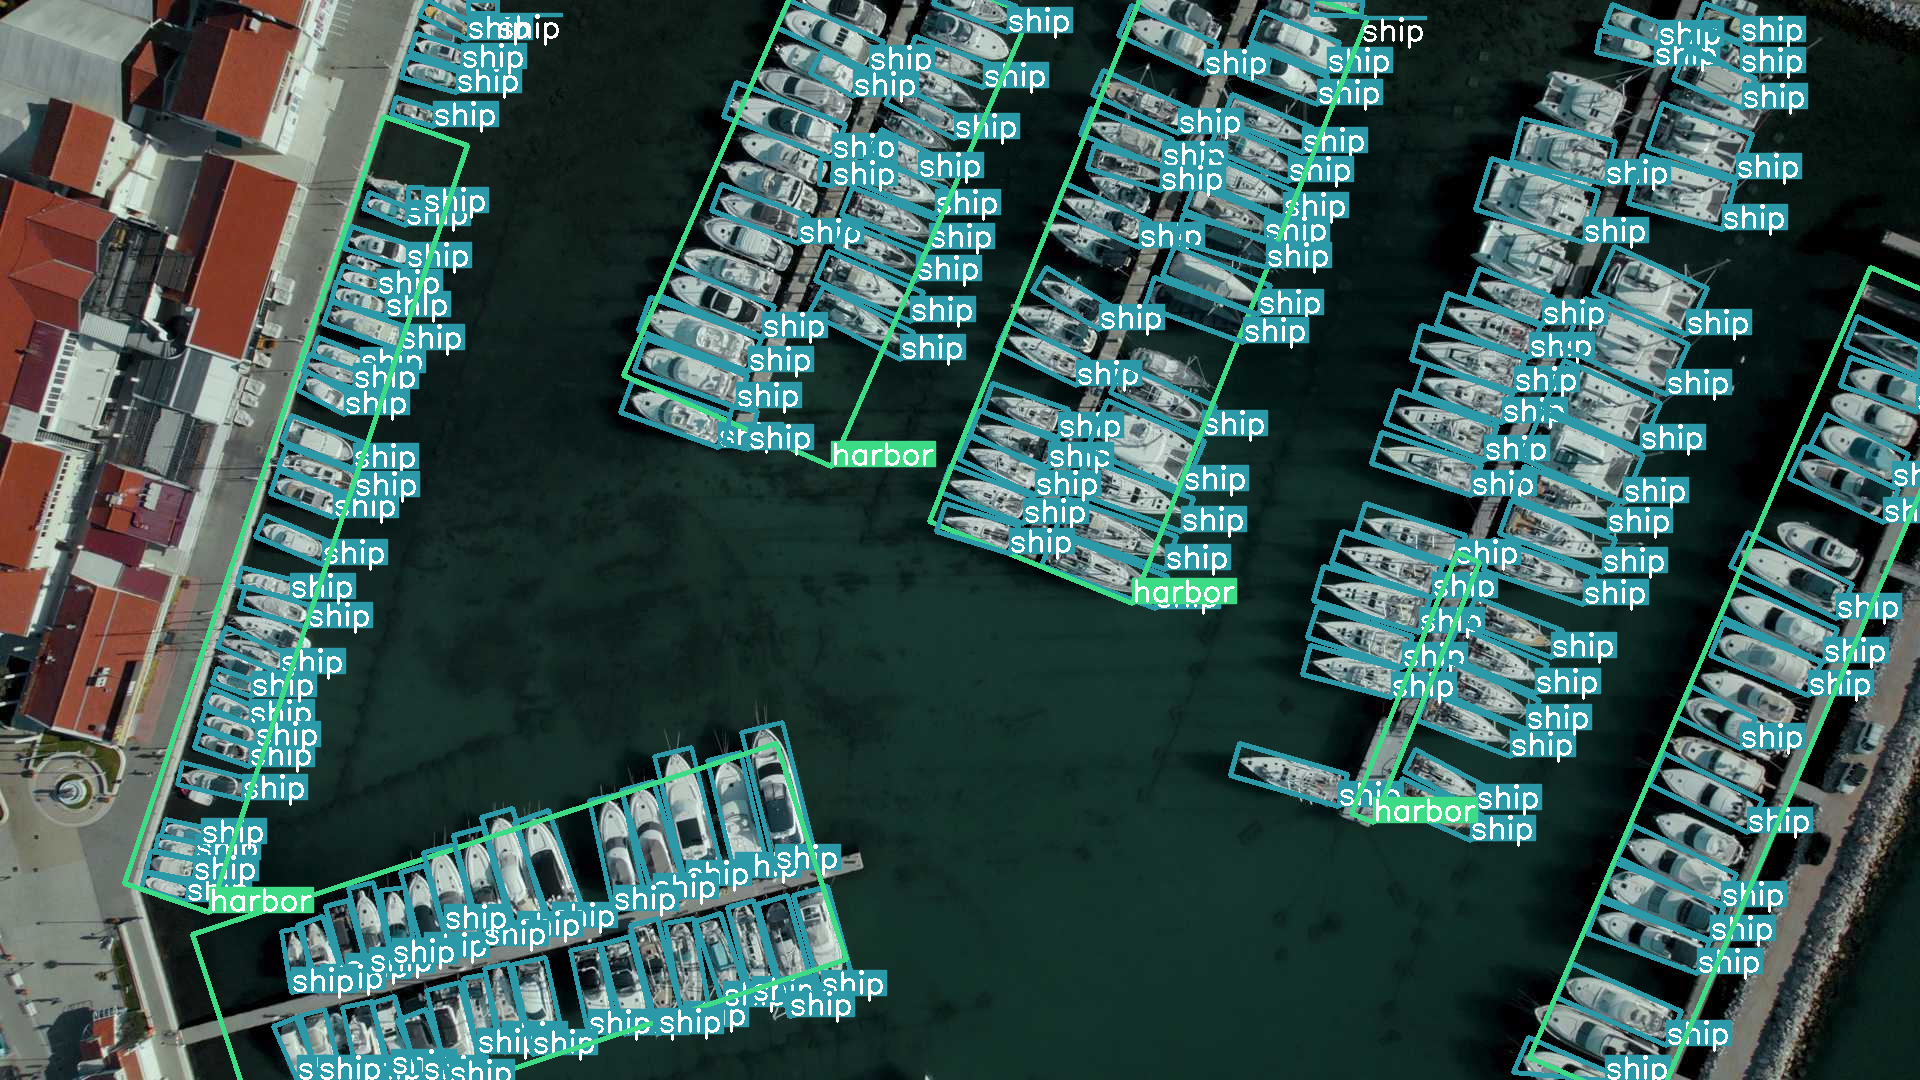

In [ ]:
result.export_visuals(export_dir="demo_data/", text_size=1, rect_th=3, hide_conf=True)

Image("demo_data/prediction_visual.png", width=800)